In [1]:
from matplotlib import pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
import os
import ast
from configparser import ConfigParser

In [3]:
DATAPATH = '../../data/output'
CONFIGPATH = '../configurations/app-remote.ini'
RESULTS = 'average_10_experiments_20211202-000820.csv'
parser = ConfigParser()
parser.read(CONFIGPATH)

# Configuration
episodes = int(parser.get("BUS", "EPISODES"))
timelimit = parser.getfloat("BUS", "TIMELIMIT") # multiplier, not the real timelimit
actions = parser.get("BUS", "ACTION_SPACE").split(',')
action_dim = len(actions)
action_resolution = parser.getint("BUS", "ACTION_SPACE_RESOLUTION")
eps = parser.getfloat("BUS", "EPS")
eps_decay = parser.getfloat("BUS", "EPS_DECAY")
eps_min = parser.getfloat("BUS", "EPS_MIN")
buffersize = int(parser.get("BUS", "BUFFERSIZE"))
min_experience = int(parser.get("BUS", "MIN_EXPERIENCE"))
target_update_threshold = int(parser.get("BUS", "TARGET_UPDATE_THRESHOLD"))
tau = parser.getfloat("BUS", "TAU")
gamma = parser.getfloat("BUS", "GAMMA")
penalty = int(parser.get("BUS", "PENALTY"))
reward = parser.getint("BUS", "REWARD")
q_net_layers = ast.literal_eval(parser.get("BUS", "DQN_LAYERS"))
batchsize = int(parser.get("BUS", "BATCHSIZE"))
lr_decay = parser.getboolean("BUS", "LR_DECAY")
lr_decay_steps = parser.getint("BUS", "LR_DECAY_STEPS")
velocity = float(parser.get("BUS", "VELOCITY"))

config = {'episodes': episodes, 
          'actions': actions,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'penalty': penalty,
          'learning rate decay': lr_decay,
          'batchsize': batchsize
         }

# Evaluate single / averaged runs

In [83]:
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# %%
# results = results[results['penalty'] == 15]
results['return_MA'] = results['return'].rolling(20).mean()
results['service_level_MA'] = results['service_level'].rolling(20).mean()

/home/jmuires/anaconda3/envs/urban-mobility-simulation/lib/python3.7/site-packages/ipykernel_launcher.py:20: UserWarning: Matplotlib is currently using module://matplotlib_inline.backend_inline, which is a non-GUI backend, so cannot show the figure.


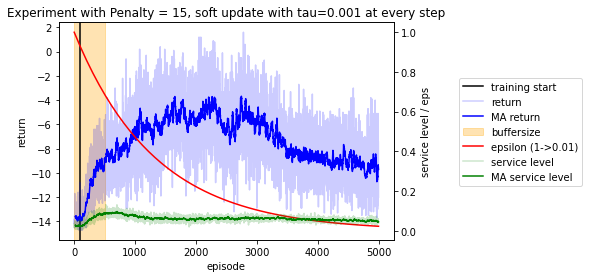

In [84]:
fig, ax = plt.subplots()
# annotations
plt.axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
plt.axvline(min_experience, color='black', label='training start')
x_ = np.linspace(1,episodes)
ax_ = plt.twinx(ax)
ax2 = ax.twinx()
sns.lineplot(x=x_, y=np.maximum(0.99925**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
ax_.set_axis_off() # hide this axis

sns.lineplot(data=results, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax, legend=False)
sns.lineplot(data=results, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
sns.lineplot(data=results, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

plt.title('Experiment with Penalty = 15, soft update with tau=0.001 at every step')
fig.patch.set_facecolor('white')
ax2.set_ylabel('service level / eps')
fig.legend(bbox_to_anchor=(1.04,0.5), loc="center left")
fig.show()

# Experiments

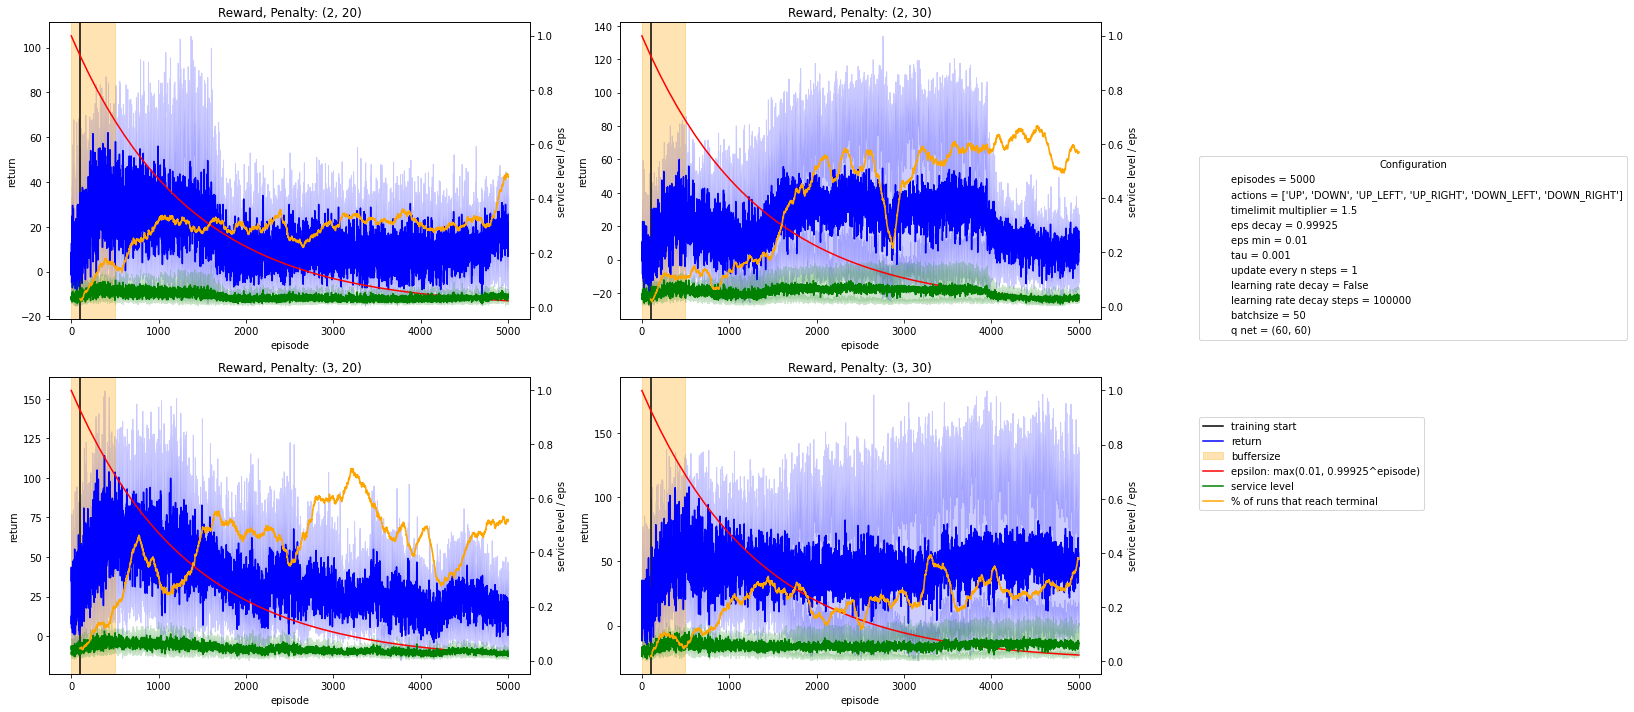

In [7]:
import matplotlib.patches as mpatches

config = {'episodes': episodes, 
          'actions': actions,
          'timelimit multiplier': timelimit,
          'eps decay': eps_decay,
          'eps min': eps_min,
          'tau': tau,
          'update every n steps': target_update_threshold,
          'penalty': penalty,
          'reward': reward,
          'learning rate decay': lr_decay,
          'learning rate decay steps': lr_decay_steps,
          'batchsize': batchsize,
          'q net': q_net_layers
         }

RESULTS = 'search_reward_experiments_20211211-172120.csv'
results = pd.read_csv(os.path.join(DATAPATH, RESULTS))

# TODO: put in variable instead of if blocks for each possible experiment

if 'buffersize' in list(results):
    fig, ax = plt.subplots(results['buffersize'].nunique(), figsize=(10,15))
    for i, (name, group) in enumerate(results.groupby('buffersize')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, name, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Buffersize: {name}')

if 'action_space' in list(results):
    experiments = results['action_space'].nunique()
    config.pop('actions') # remove this from configuration legend
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('action_space')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()

        sns.lineplot(data=group, x='episode', y='return', alpha=.2, color='blue', label='return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', alpha=.2, color='green', label='service level', ax=ax2, legend=False)
        sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Action space: {name}')
        
if 'lr_decay' in list(results):
    experiments = results['lr_decay'].nunique()
    config.pop('learning rate decay') # remove this from configuration legend
    fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby('lr_decay')):
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[i].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[i].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[i].twinx()
        ax2 = ax[i].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon (1->{eps_min})', legend=False)
        # hide this axis
        ax_.set_axis_off()
        
        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[i], legend=False)
#         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
#         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)

        ax2.set_ylabel('service level / eps')
        ax[i].set_title(f'Decaying Learning Rate: {name}')
        
if 'reward' in list(results):
    experiments = results['reward'].nunique()
    config.pop('reward') # remove this from configuration legend
    if 'penalty' in list(results):
        config.pop('penalty')
        experiments2nd = results['penalty'].nunique()
        fig, ax = plt.subplots(experiments, experiments2nd, figsize=(8*experiments2nd,5*experiments))
    else:
        fig, ax = plt.subplots(experiments, figsize=(10,5*experiments))
    for i, (name, group) in enumerate(results.groupby(['reward', 'penalty'])):
        if i>=2:
            ax_i = 1
            ax_ii = i-2
        else:
            ax_i = 0
            ax_ii = i
        group = group.join(group.groupby('episode')['reached_destination'].mean().rolling(100).mean(), on='episode', rsuffix='_MA')
        group['return_MA'] = group['return'].rolling(20).mean()
        group['service_level_MA'] = group['service_level'].rolling(20).mean()

        # annotations
        ax[ax_i][ax_ii].axvspan(0, buffersize, color='orange', alpha=.3, label='buffersize')
        ax[ax_i][ax_ii].axvline(min_experience, color='black', label='training start')

        x_ = np.linspace(1,episodes)
        ax_ = ax[ax_i][ax_ii].twinx()
        ax2 = ax[ax_i][ax_ii].twinx()
        sns.lineplot(x=x_, y=np.maximum(eps_decay**x_, eps_min), color='red', ax=ax2, label=f'epsilon: max({eps_min}, {eps_decay}^episode)', legend=False)
        # hide this axis
        ax_.set_axis_off()
        
        sns.lineplot(data=group, x='episode', y='return', color='blue', label='return', ax=ax[ax_i][ax_ii], legend=False)
#         sns.lineplot(data=group, x='episode', y='return_MA', alpha=1, color='blue', label='MA return', ax=ax[i], legend=False)
        sns.lineplot(data=group, x='episode', y='service_level', color='green', label='service level', ax=ax2, legend=False)
#         sns.lineplot(data=group, x='episode', y='service_level_MA', alpha=1, color='green', label='MA service level', ax=ax2, legend=False)
        sns.lineplot(data=group[group.duplicated(subset=['episode'])], x='episode', y='reached_destination_MA', color='orange', label='% of runs that reach terminal', ax=ax2, legend=False)
    
        ax2.set_ylabel('service level / eps')
        ax[ax_i][ax_ii].set_title(f'Reward, Penalty: {name}')

handles, labels = [(a + b) for a, b in zip(ax[ax_i][ax_ii].get_legend_handles_labels(), ax2.get_legend_handles_labels())]
fig.patch.set_facecolor('white')
fig.tight_layout()
# fig.suptitle('Experiment with Penalty = 15, soft update with tau=0.001 at every step', fontsize=15)
# fig.subplots_adjust(top=0.95)
lgd = fig.legend(handles, labels, bbox_to_anchor=(1.04,0.35), loc="center left")
config_handles = []
for k,v in config.items():
    config_handles.append(mpatches.Patch(color='none', label=f'{k} = {v}'))
lgd2 = fig.legend(handles=config_handles, bbox_to_anchor=(1.04,0.65), loc="center left", title="Configuration")

plt.savefig(os.path.join(DATAPATH, RESULTS.replace('.csv', '.png')), bbox_extra_artists=(lgd,lgd2), bbox_inches='tight')
plt.show()

## does it reach the terminal destination?

In [ ]:
fig, ax = plt.subplots()
sns.lineplot(ax=ax, data=results, x='episode', y='return', hue='reached_destination')
reached = results.groupby('episode')['reached_destination'].mean().rolling(100).mean().reset_index()
ax2 = ax.twinx()
sns.lineplot(ax=ax2, data=reached, x='episode', y='reached_destination', color='black', alpha=.2)

# Benchmark

In [44]:
BENCHMARK = '10_episodes_benchmark_20211210-213847.csv'
ROLLING = 1

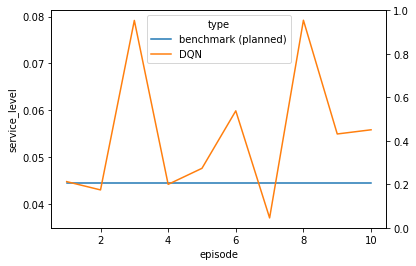

In [50]:
fig, ax = plt.subplots()
benchmark_results = pd.read_csv(os.path.join(DATAPATH, BENCHMARK))
# benchmark_results.loc[10, 'reached_destination'] = False # for debugging

benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='DQN', 'service_level'].rolling(ROLLING).mean()
benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level_MA'] = benchmark_results.loc[benchmark_results['type']=='benchmark (planned)', 'service_level'].rolling(ROLLING).mean()

sns.lineplot(ax=ax, data=benchmark_results, x='episode', y='service_level', hue='type')
benchmark_results['notreached'] = benchmark_results.apply(lambda x: 1 if not x['reached_destination'] else 0, axis=1)
ax2 = ax.twinx()
# sns.barplot(ax=ax2, data=benchmark_results, x='episode', y='notreached', color='red', alpha=.4)
plt.show()

In [41]:
benchmark_results

,episode,type,reached_destination,service_level,service_level_MA,notreached
0,1,benchmark (planned),True,0.044534,NaN,0
1,2,benchmark (planned),True,0.044534,NaN,0
2,3,benchmark (planned),True,0.044534,NaN,0
3,4,benchmark (planned),True,0.044534,NaN,0
4,5,benchmark (planned),True,0.044534,NaN,0
5,6,benchmark (planned),True,0.044534,NaN,0
6,7,benchmark (planned),True,0.044534,NaN,0
7,8,benchmark (planned),True,0.044534,NaN,0
8,9,benchmark (planned),True,0.044534,NaN,0
9,10,benchmark (planned),True,0.044534,NaN,0


In [46]:
benchmark_results.groupby('type').describe()['service_level']

,count,mean,std,min,25%,50%,75%,max
type,,,,,,,,
DQN,10.0,0.054568,0.014662,0.037037,0.044343,0.051282,0.058870,0.079208
benchmark (planned),10.0,0.044534,0.000000,0.044534,0.044534,0.044534,0.044534,0.044534
